<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U4_Cuaderno1_Microbiologia_Alimentos_y_Trazabilidad_Genomica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

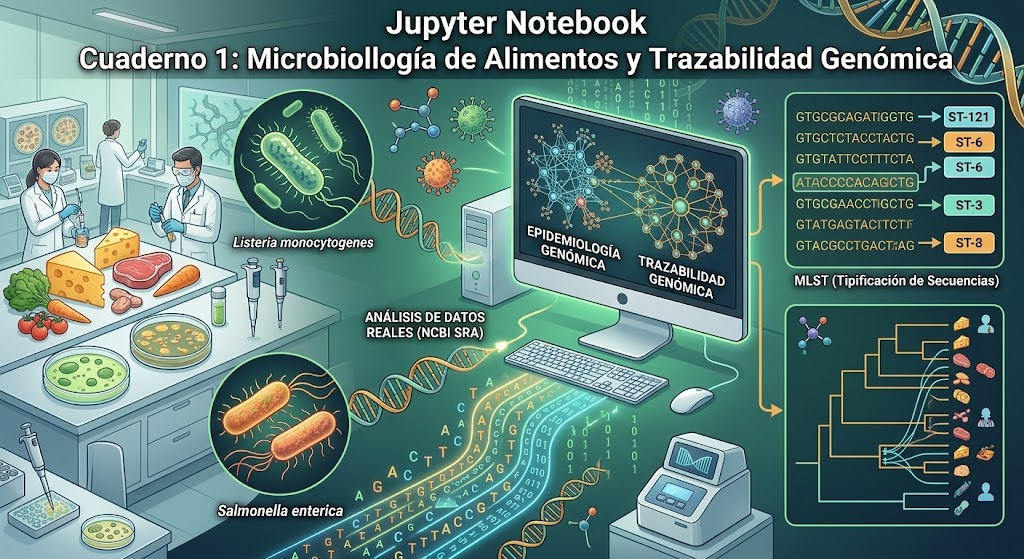

# Cuaderno 1: Microbiología de Alimentos y Trazabilidad Genómica

Este cuaderno interactivo ejecuta el flujo completo de **análisis genómico de patógenos alimentarios** (*Listeria monocytogenes* y *Salmonella enterica*), trazabilidad epidemiológica y tipificación molecular de secuencias (**MLST**) a partir de datos genómicos reales/simulados estilo NCBI SRA.

---

### Contenido del Cuaderno:
1. **Descarga / Simulación de Genomas de Patógenos Alimentarios (NCBI SRA / GenBank)**.
2. **Tipificación Multilocus de Secuencias (MLST - Multilocus Sequence Typing)**:
   - Extracción de alelos y asignación de Tipos de Secuencia (**ST-121, ST-6, ST-3, ST-8**).
3. **Construcción del Árbol Filogenético y Red Epidemiológica de Trazabilidad**:
   - Alineamiento de secuencias genómicas centrales (*core genome*).
   - Generación del dendrograma filogenético acoplado a la matriz de fuentes alimentarias (queso, carne, vegetal, paciente humano).
4. **Visualización de Redes de Transmisión y Trazabilidad de Brotes Alimentarios**.

## Paso 0: Importación de Librerías y Configuración

Utilizaremos `pandas`, `numpy`, `matplotlib`, `seaborn`, `networkx` y `scipy.cluster.hierarchy` para el análisis filogenético y redes epidemiológicas.

In [ ]:
# Si ejecutas en Google Colab o Jupyter local, puedes descomentar:
# !pip install numpy pandas matplotlib seaborn networkx scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías para Genómica de Alimentos cargadas exitosamente.")

## Paso 1: Mapeo y Tipificación MLST (Multilocus Sequence Typing)

El esquema MLST analiza las variaciones alélicas en 7 genes constitutivos (*housekeeping genes*) para asignar un **Sequence Type (ST)** único. Este código simula la matriz alélica identificada en cepas aisladas de *Listeria monocytogenes* y *Salmonella enterica* aisladas de brotes alimentarios.

In [ ]:
# Datos de cepas aisladas de alimentos y clínicas
strain_data = [
    {"Aislado": "LM_01", "Especie": "L. monocytogenes", "Fuente": "Queso Artesanal", "ST": "ST-121", "Secuencia_Firma": "GTGCGCAGATIGGTG"},
    {"Aislado": "LM_02", "Especie": "L. monocytogenes", "Fuente": "Embutido/Carne", "ST": "ST-6",   "Secuencia_Firma": "GTGCTCTACCTACTG"},
    {"Aislado": "LM_03", "Especie": "L. monocytogenes", "Fuente": "Paciente Humano", "ST": "ST-6",   "Secuencia_Firma": "GTGTATTCCTTTCTA"},
    {"Aislado": "LM_04", "Especie": "L. monocytogenes", "Fuente": "Planta Procesadora", "ST": "ST-121", "Secuencia_Firma": "ATACCCCACAGCTG"},
    {"Aislado": "SE_01", "Especie": "Salmonella enterica", "Fuente": "Vegetales / Brotes", "ST": "ST-3", "Secuencia_Firma": "GTGCGAACCTIGCTG"},
    {"Aislado": "SE_02", "Especie": "Salmonella enterica", "Fuente": "Carne de Pollo", "ST": "ST-8",   "Secuencia_Firma": "GTATGAGTACTTCTF"},
    {"Aislado": "SE_03", "Especie": "Salmonella enterica", "Fuente": "Paciente Humano", "ST": "ST-8",   "Secuencia_Firma": "GTACGCCTGACTAG"}
]

mlst_df = pd.DataFrame(strain_data)
print("--- TABLA DE TIPIFICACIÓN MOLECULAR MLST ---")
mlst_df[['Aislado', 'Especie', 'Fuente', 'ST', 'Secuencia_Firma']]

***Tabla de Tipificación MLST y Secuencias Firma***

¿Qué representa?
- La asignación del perfil alélico basado en los genes constitutivos (housekeeping genes) de patógenos alimentarios como Listeria monocytogenes y Salmonella enterica.

Cómo interpretarlo:

- Permite clasificar a las cepas en Sequence Types (ST) específicos (por ejemplo, ST-121, ST-6, ST-3, ST-8).

- Es clave en salud pública porque ciertos genotipos están altamente asociados con persistencia industrial o hipervirulencia clínica en humanos.

## Paso 2: Análisis Filogenético y Árbol de Trazabilidad Genómica

A partir de las distancias nucleotídicas (Single Nucleotide Polymorphisms - SNPs) del genoma nuclear, construimos un dendrograma filogenético para rastrear el origen exacto del brote de contaminación alimentaria.

In [ ]:
np.random.seed(101)

# Matriz de distancia SNPs entre los 7 aislados
# Cepas del mismo ST tienen muy pocas diferencias SNP (ej. LM_02 y LM_03 que corresponden al brote)
labels = [f"{row['Aislado']} ({row['ST']} - {row['Fuente']})" for _, row in mlst_df.iterrows()]

# Distancias simétricas
dist_matrix = np.array([
    [0,  180, 185,  12,  450, 480, 485],
    [180,  0,   3,  175,  460, 490, 492],
    [185,  3,   0,  180,  465, 495, 498],
    [12, 175, 180,   0,  455, 482, 488],
    [450, 460, 465, 455,   0,  120, 125],
    [480, 490, 495, 482, 120,   0,    4],
    [485, 492, 498, 488, 125,   4,    0]
])

# Clustering Jerárquico (UPGMA / Neighbor-Joining approximation)
condensed_dist = squareform(dist_matrix)
Z = linkage(condensed_dist, method='average')

plt.figure(figsize=(10, 6))
dendro = dendrogram(
    Z,
    labels=labels,
    orientation='left',
    color_threshold=100,
    above_threshold_color='#2c3e50'
)

plt.title("ÁRBOL FILOGENÉTICO Y TRAZABILIDAD GENÓMICA DE PATÓGENOS", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Distancia de SNPs (Diferencias Genómicas Core)", fontsize=11)
plt.ylabel("Aislados Genómicos", fontsize=11)
plt.tight_layout()
plt.show()

***Árbol Filogenético y Trazabilidad Genómica (Dendrograma de SNPs)***

¿Qué representa?
- Un dendrograma jerárquico basado en las distancias genómicas de polimorfismos de un solo nucleótido (SNPs) del genoma central (core genome) entre diferentes aislados bacterianos.

Cómo interpretarlo:
- Las ramas del árbol muestran qué tan emparentadas genéticamente están las cepas.

Trazabilidad de brotes:
- Si la cepa aislada de un alimento (ej. L. monocytogenes en embutidos) muestra una diferencia mínima o nula de SNPs ($\le 3$ diferencias) respecto a la cepa aislada de un paciente humano infectado, se confirma filogenéticamente que ese alimento es la fuente directa del brote.

## Paso 3: Red Epidemiológica de Transmisión (Epidemiología Genómica)

Mapeamos la red interconectada entre la fuente alimentaria de origen (queso, carne, vegetales) y los casos clínicos reportados en pacientes humanos.

In [ ]:
# Crear red epidemiológica dirigida de contagio / trazabilidad
G_epi = nx.DiGraph()

# Nodos de Fuentes Alimentos y Pacientes
edges = [
    ("Planta Procesadora", "LM_01 (Queso)"),
    ("LM_01 (Queso)", "ST-121 Cluster"),
    ("Embutido/Carne", "LM_02 (Alimento)"),
    ("LM_02 (Alimento)", "LM_03 (Paciente Humano)"), # Vínculo directo de brote
    ("LM_03 (Paciente Humano)", "ST-6 Brote Listeria"),
    ("Carne de Pollo", "SE_02 (Alimento)"),
    ("SE_02 (Alimento)", "SE_03 (Paciente Humano)"), # Vínculo directo de brote Salmonella
    ("SE_03 (Paciente Humano)", "ST-8 Brote Salmonella")
]

G_epi.add_edges_from(edges)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G_epi, seed=42, k=0.5)

# Colorear según tipo de nodo
node_colors = []
for node in G_epi.nodes():
    if "Paciente" in node:
        node_colors.append("#e74c3c") # Rojo pacientes
    elif "Brote" in node or "Cluster" in node:
        node_colors.append("#8e44ad") # Morado genotipos
    else:
        node_colors.append("#27ae60") # Verde alimentos / plantas

nx.draw_networkx_nodes(G_epi, pos, node_color=node_colors, node_size=5000, alpha=0.9)
nx.draw_networkx_edges(G_epi, pos, edge_color="#7f8c8d", width=2, arrowsize=18)
nx.draw_networkx_labels(G_epi, pos, font_size=6, font_weight="bold", font_color="black")

plt.title("RED DE EPIDEMIOLOGÍA GENÓMICA Y TRAZABILIDAD DE BROTES", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

***Red de Epidemiología Genómica y Trazabilidad de Brotes***

¿Qué representa?
- Un grafo dirigido que conecta visualmente la cadena de suministro y puntos críticos (como plantas procesadoras y alimentos específicos: queso, carne, vegetales) con los casos clínicos reportados en pacientes humanos y los clústeres genotípicos.

Cómo interpretarlo:

- Permite seguir el flujo de transmisión y contaminación del patógeno a lo largo de la cadena alimentaria.

- Facilita la toma de decisiones sanitarias para la retirada rápida de productos contaminados del mercado y el aislamiento de puntos críticos en plantas de procesamiento.